In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import json
import joblib
import time

from scipy import sparse

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve
)



RANDOM_STATE = 42

Load experiment metadata and target arrays

In [3]:
model_data_dir = (
    "/content/drive/MyDrive/model_processed/pilot_2014q1"
)

with open(
    os.path.join(model_data_dir, "metadata.json"),
    "r"
) as f:
    metadata = json.load(f)

experiments = metadata["experiments"]

y_train = np.load(
    os.path.join(model_data_dir, "targets/y_train.npy")
)

y_val = np.load(
    os.path.join(model_data_dir, "targets/y_val.npy")
)

y_test = np.load(
    os.path.join(model_data_dir, "targets/y_test.npy")
)

print("Dataset:", metadata["dataset"])

print("\nAvailable experiments:")

for name, features in experiments.items():
    print(name, ":", len(features), "raw features")

print("\nTarget array shapes:")
print("Training:", y_train.shape)
print("Validation:", y_val.shape)
print("Testing:", y_test.shape)

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts())

print("\nTraining positive percentage:",
      round(y_train.mean() * 100, 4))

print("\nLibrary versions used during preprocessing:")
print(metadata["library_versions"])

Dataset: AEOLUS_FAERS_2014Q1_Pilot

Available experiments:
E1_Basic : 3 raw features
E2_Extended : 6 raw features
E3_Contextual : 9 raw features

Target array shapes:
Training: (175871,)
Validation: (37687,)
Testing: (37687,)

Training class distribution:
0    172143
1      3728
Name: count, dtype: int64

Training positive percentage: 2.1197

Library versions used during preprocessing:
{'python': '3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]', 'pandas': '2.2.3', 'numpy': '2.4.6', 'scikit_learn': '1.6.1', 'scipy': '1.16.3'}


Load encoded feature matrix

In [4]:
experiment_data = {}

for name in experiments:

    experiment_dir = os.path.join(
        model_data_dir, name
    )

    X_train = sparse.load_npz(
        os.path.join(experiment_dir, "X_train.npz")
    )

    X_val = sparse.load_npz(
        os.path.join(experiment_dir, "X_val.npz")
    )

    X_test = sparse.load_npz(
        os.path.join(experiment_dir, "X_test.npz")
    )

    with open(
        os.path.join(experiment_dir, "feature_names.json"),
        "r"
    ) as f:
        feature_names = json.load(f)

    assert X_train.shape[0] == len(y_train)
    assert X_val.shape[0] == len(y_val)
    assert X_test.shape[0] == len(y_test)

    assert (
        X_train.shape[1]
        == X_val.shape[1]
        == X_test.shape[1]
        == len(feature_names)
    )

    experiment_data[name] = {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "feature_names": feature_names
    }

    print(f"\n{name}")
    print("Training:", X_train.shape)
    print("Validation:", X_val.shape)
    print("Testing:", X_test.shape)

print("\nAll experiments loaded successfully.")


E1_Basic
Training: (175871, 677)
Validation: (37687, 677)
Testing: (37687, 677)

E2_Extended
Training: (175871, 1004)
Validation: (37687, 1004)
Testing: (37687, 1004)

E3_Contextual
Training: (175871, 1664)
Validation: (37687, 1664)
Testing: (37687, 1664)

All experiments loaded successfully.


Establish a naive baseline

In [5]:
from sklearn.dummy import DummyClassifier

X_train_basic = experiment_data["E1_Basic"]["X_train"]
X_val_basic = experiment_data["E1_Basic"]["X_val"]

dummy_model = DummyClassifier(
    strategy="prior",
    random_state=RANDOM_STATE
)

dummy_model.fit(X_train_basic, y_train)

dummy_predictions = dummy_model.predict(X_val_basic)

dummy_probabilities = dummy_model.predict_proba(
    X_val_basic
)[:, 1]

dummy_results = {
    "Model": "Dummy Classifier",
    "Accuracy": accuracy_score(
        y_val, dummy_predictions
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, dummy_predictions
    ),
    "Precision": precision_score(
        y_val, dummy_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, dummy_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_val, dummy_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_val, dummy_probabilities
    ),
    "Average Precision": average_precision_score(
        y_val, dummy_probabilities
    )
}

display(
    pd.DataFrame([dummy_results]).round(4)
)

print("\nConfusion matrix:")

display(
    confusion_matrix(y_val, dummy_predictions)
)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Dummy Classifier,0.9788,0.5,0.0,0.0,0.0,0.5,0.0212



Confusion matrix:


array([[36888,     0],
       [  799,     0]])

Implement Logistic Regression

In [6]:
lr_config = {
    "penalty": "l2",
    "C": 1.0,
    "solver": "lbfgs",
    "class_weight": "balanced",
    "max_iter": 1000,
    "random_state": RANDOM_STATE
}

print("Logistic Regression configuration:")

for parameter, value in lr_config.items():
    print(f"{parameter}: {value}")

Logistic Regression configuration:
penalty: l2
C: 1.0
solver: lbfgs
class_weight: balanced
max_iter: 1000
random_state: 42


In [7]:
def evaluate_model(
    y_true,
    probabilities,
    threshold=0.5
):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_true, predictions
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_true, predictions
        ),

        "Precision": precision_score(
            y_true, predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true, predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_true, predictions,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),

        "Average Precision": average_precision_score(
            y_true, probabilities
        ),

        "Specificity": tn / (tn + fp),

        "True Negatives": int(tn),
        "False Positives": int(fp),
        "False Negatives": int(fn),
        "True Positives": int(tp)
    }

In [8]:
lr_models = {}
lr_val_probabilities = {}
lr_results = []

for name, data in experiment_data.items():

    print("\n" + "=" * 60)
    print(f"Training Logistic Regression: {name}")
    print("=" * 60)

    X_train = data["X_train"]
    X_val = data["X_val"]

    model = LogisticRegression(**lr_config)

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    training_time = time.perf_counter() - start_time

    val_probabilities = model.predict_proba(
        X_val
    )[:, 1]

    results = evaluate_model(
        y_val,
        val_probabilities,
        threshold=0.5
    )

    results["Model"] = "Logistic Regression"
    results["Experiment"] = name
    results["Encoded Features"] = X_train.shape[1]
    results["Training Time (s)"] = training_time
    results["Iterations"] = int(model.n_iter_.max())

    lr_models[name] = model

    lr_val_probabilities[name] = val_probabilities

    lr_results.append(results)

    print(f"Training time: {training_time:.2f} seconds")
    print("Iterations:", model.n_iter_)

    print(f"ROC-AUC: {results['ROC-AUC']:.4f}")
    print(
        f"Average Precision: "
        f"{results['Average Precision']:.4f}"
    )
    print(f"Precision: {results['Precision']:.4f}")
    print(f"Recall: {results['Recall']:.4f}")
    print(f"F1-score: {results['F1']:.4f}")

print("\nAll Logistic Regression models trained.")


Training Logistic Regression: E1_Basic
Training time: 4.64 seconds
Iterations: [132]
ROC-AUC: 0.7747
Average Precision: 0.1408
Precision: 0.0580
Recall: 0.6370
F1-score: 0.1063

Training Logistic Regression: E2_Extended
Training time: 7.01 seconds
Iterations: [183]
ROC-AUC: 0.7881
Average Precision: 0.1627
Precision: 0.0605
Recall: 0.6433
F1-score: 0.1106

Training Logistic Regression: E3_Contextual
Training time: 7.49 seconds
Iterations: [266]
ROC-AUC: 0.7971
Average Precision: 0.1491
Precision: 0.0640
Recall: 0.6496
F1-score: 0.1165

All Logistic Regression models trained.


Generate comparison table

In [9]:
lr_results_df = pd.DataFrame(lr_results)

comparison_columns = [
    "Model",
    "Experiment",
    "Encoded Features",
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "Average Precision",
    "Specificity",
    "Training Time (s)"
]

display(
    lr_results_df[comparison_columns]
    .round(4)
)

,Model,Experiment,Encoded Features,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,Specificity,Training Time (s)
0,Logistic Regression,E1_Basic,677,0.7729,0.7065,0.0580,0.6370,0.1063,0.7747,0.1408,0.7759,4.6448
1,Logistic Regression,E2_Extended,1004,0.7806,0.7134,0.0605,0.6433,0.1106,0.7881,0.1627,0.7836,7.0072
2,Logistic Regression,E3_Contextual,1664,0.7911,0.7218,0.0640,0.6496,0.1165,0.7971,0.1491,0.7941,7.4948


In [10]:
dummy_comparison = dummy_results.copy()

dummy_comparison["Experiment"] = "Naive Baseline"

all_baseline_results = pd.concat(
    [
        pd.DataFrame([dummy_comparison]),
        lr_results_df
    ],
    ignore_index=True
)

display(
    all_baseline_results[
        [
            "Model",
            "Experiment",
            "Accuracy",
            "Balanced Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "Average Precision"
        ]
    ].round(4)
)

,Model,Experiment,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Dummy Classifier,Naive Baseline,0.9788,0.5000,0.0000,0.0000,0.0000,0.5000,0.0212
1,Logistic Regression,E1_Basic,0.7729,0.7065,0.0580,0.6370,0.1063,0.7747,0.1408
2,Logistic Regression,E2_Extended,0.7806,0.7134,0.0605,0.6433,0.1106,0.7881,0.1627
3,Logistic Regression,E3_Contextual,0.7911,0.7218,0.0640,0.6496,0.1165,0.7971,0.1491


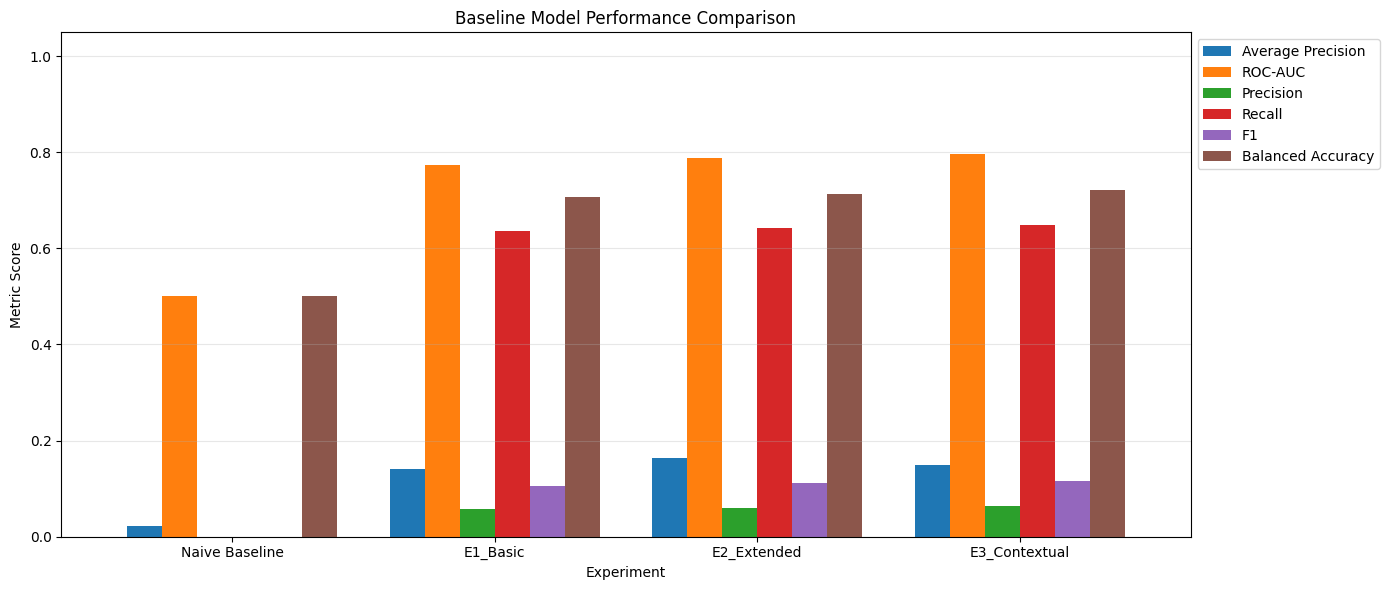

In [11]:
metrics_to_plot = [
    "Average Precision",
    "ROC-AUC",
    "Precision",
    "Recall",
    "F1",
    "Balanced Accuracy"
]

plot_df = all_baseline_results.set_index(
    "Experiment"
)[metrics_to_plot]

ax = plot_df.plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title(
    "Baseline Model Performance Comparison"
)

plt.ylabel("Metric Score")
plt.xlabel("Experiment")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

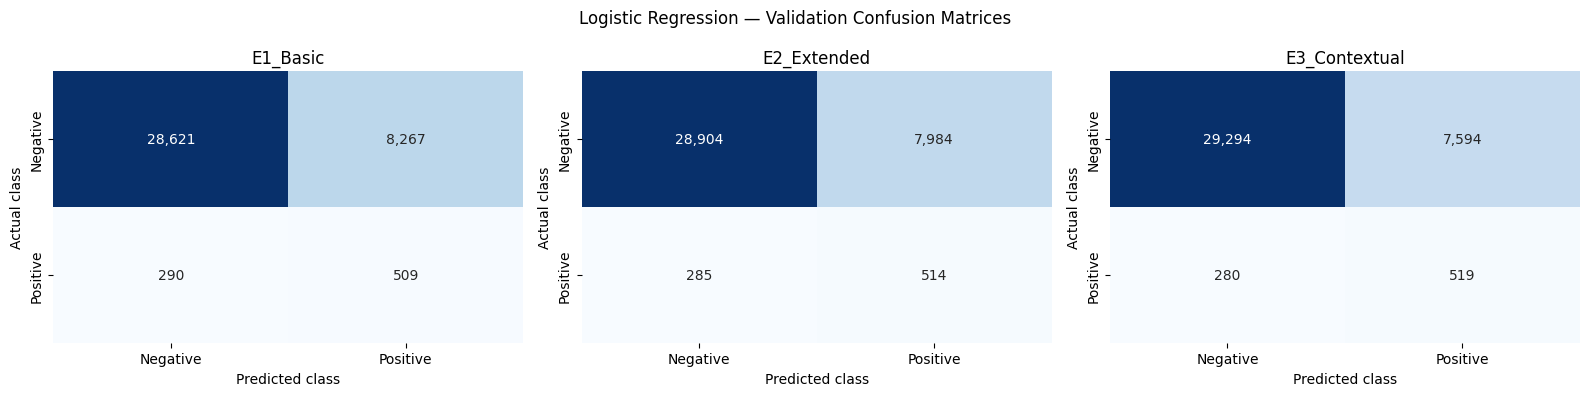

In [12]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4)
)

for ax, (name, probabilities) in zip(
    axes,
    lr_val_probabilities.items()
):

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    cm = confusion_matrix(
        y_val, predictions
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt=",d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.suptitle(
    "Logistic Regression — Validation Confusion Matrices"
)

plt.tight_layout()
plt.show()

In [13]:
def find_optimal_threshold(y_true, probabilities):

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    # The final precision and recall values have no threshold
    precision = precision[:-1]
    recall = recall[:-1]

    f1_scores = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision),
        where=(precision + recall) != 0
    )

    best_index = np.argmax(f1_scores)

    return {
        "Optimal Threshold": float(thresholds[best_index]),
        "Precision": float(precision[best_index]),
        "Recall": float(recall[best_index]),
        "F1": float(f1_scores[best_index])
    }

In [14]:
lr_optimal_thresholds = {}
lr_optimized_results = []

for name, probabilities in lr_val_probabilities.items():

    threshold_result = find_optimal_threshold(
        y_val,
        probabilities
    )

    optimal_threshold = threshold_result[
        "Optimal Threshold"
    ]

    lr_optimal_thresholds[name] = optimal_threshold

    results = evaluate_model(
        y_val,
        probabilities,
        threshold=optimal_threshold
    )

    results["Model"] = "Logistic Regression"
    results["Experiment"] = name

    lr_optimized_results.append(results)

    print(f"\n{name}")
    print(f"Optimal threshold: {optimal_threshold:.4f}")
    print(f"Precision: {results['Precision']:.4f}")
    print(f"Recall: {results['Recall']:.4f}")
    print(f"F1-score: {results['F1']:.4f}")

lr_optimized_results_df = pd.DataFrame(
    lr_optimized_results
)


E1_Basic
Optimal threshold: 0.8456
Precision: 0.1898
Recall: 0.2666
F1-score: 0.2218

E2_Extended
Optimal threshold: 0.8556
Precision: 0.2135
Recall: 0.2741
F1-score: 0.2400

E3_Contextual
Optimal threshold: 0.8767
Precision: 0.2241
Recall: 0.2653
F1-score: 0.2430


In [15]:
threshold_comparison = []

for name in experiments:

    default = lr_results_df[
        lr_results_df["Experiment"] == name
    ].iloc[0]

    optimized = lr_optimized_results_df[
        lr_optimized_results_df["Experiment"] == name
    ].iloc[0]

    threshold_comparison.append({
        "Experiment": name,

        "Default Threshold": 0.5,
        "Optimized Threshold": optimized["Threshold"],

        "Default Precision": default["Precision"],
        "Optimized Precision": optimized["Precision"],

        "Default Recall": default["Recall"],
        "Optimized Recall": optimized["Recall"],

        "Default F1": default["F1"],
        "Optimized F1": optimized["F1"],

        "F1 Improvement (%)": (
            (optimized["F1"] - default["F1"])
            / default["F1"] * 100
        )
    })

threshold_comparison_df = pd.DataFrame(
    threshold_comparison
)

display(threshold_comparison_df.round(4))

,Experiment,Default Threshold,Optimized Threshold,Default Precision,Optimized Precision,Default Recall,Optimized Recall,Default F1,Optimized F1,F1 Improvement (%)
0,E1_Basic,0.5,0.8456,0.0580,0.1898,0.6370,0.2666,0.1063,0.2218,108.5803
1,E2_Extended,0.5,0.8556,0.0605,0.2135,0.6433,0.2741,0.1106,0.2400,117.0506
2,E3_Contextual,0.5,0.8767,0.0640,0.2241,0.6496,0.2653,0.1165,0.2430,108.6163


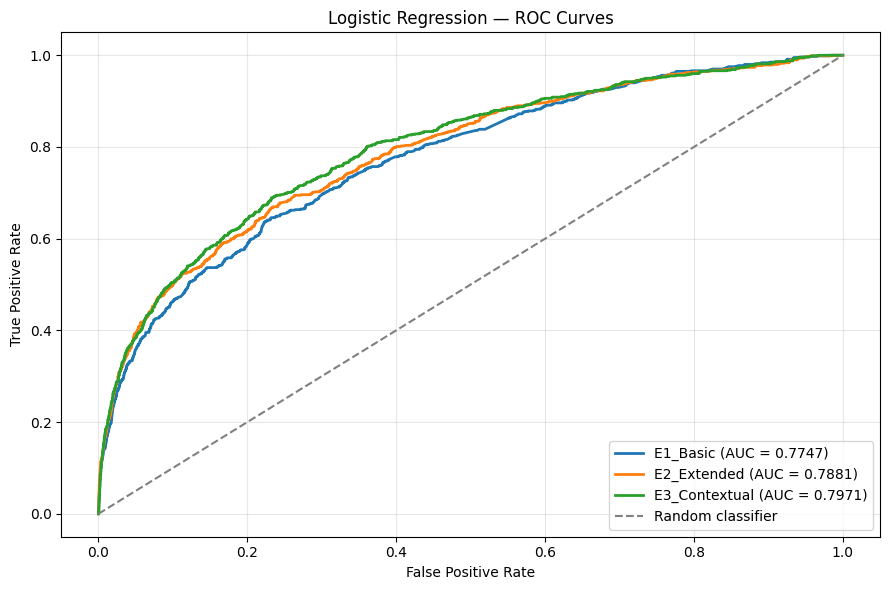

In [16]:
plt.figure(figsize=(9, 6))

for name, probabilities in lr_val_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_val,
        probabilities
    )

    auc_score = roc_auc_score(
        y_val,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression — ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

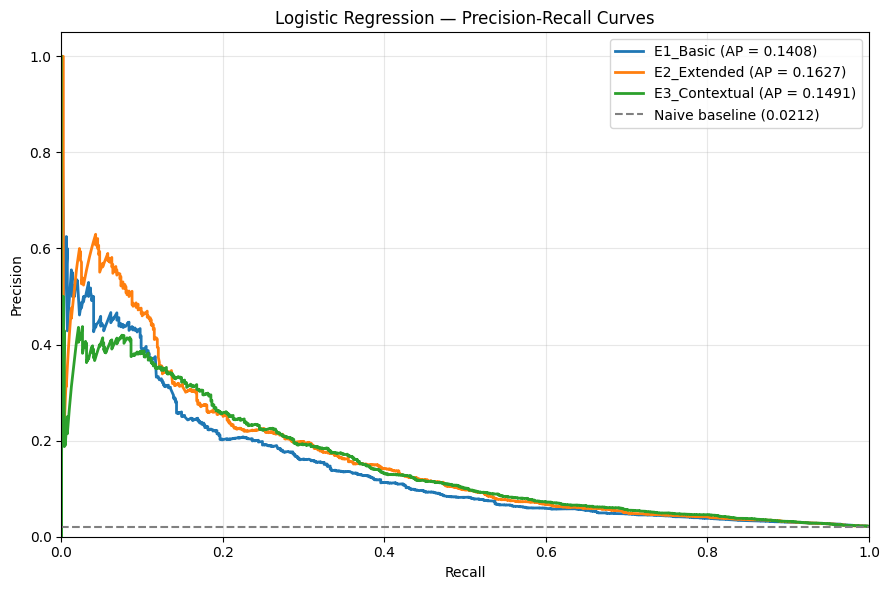

In [17]:
plt.figure(figsize=(9, 6))

for name, probabilities in lr_val_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_val,
        probabilities
    )

    ap_score = average_precision_score(
        y_val,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP = {ap_score:.4f})"
    )

plt.axhline(
    y=y_val.mean(),
    linestyle="--",
    color="gray",
    label=f"Naive baseline ({y_val.mean():.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Logistic Regression — Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

Generate optimized confusion matricesGenerate optimized confusion matrices

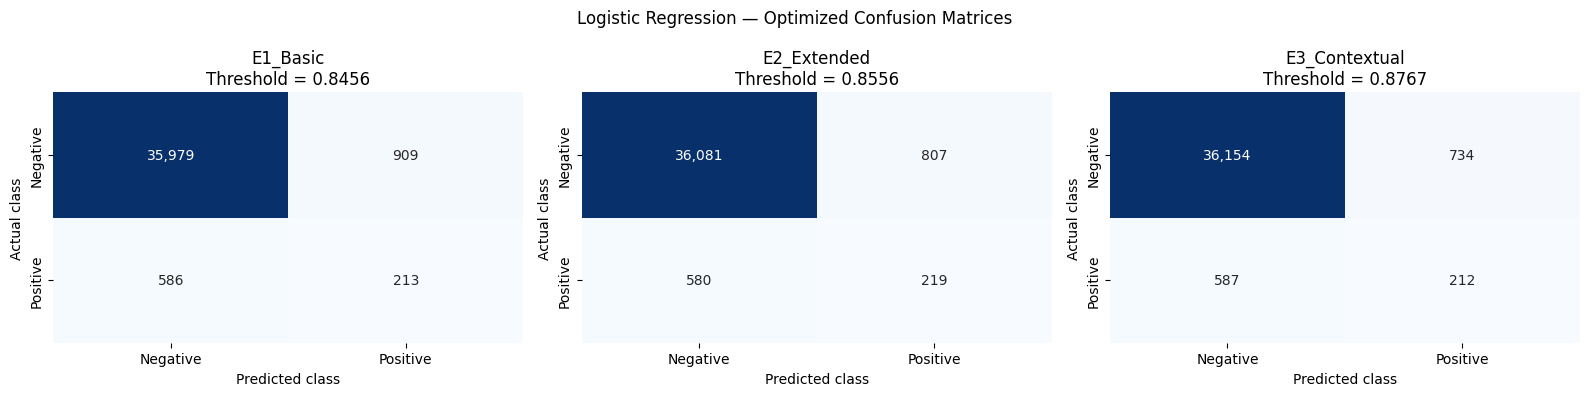

In [18]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4)
)

for ax, (name, probabilities) in zip(
    axes,
    lr_val_probabilities.items()
):

    threshold = lr_optimal_thresholds[name]

    predictions = (
        probabilities >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt=",d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(
        f"{name}\nThreshold = {threshold:.4f}"
    )

    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

plt.suptitle(
    "Logistic Regression — Optimized Confusion Matrices"
)

plt.tight_layout()
plt.show()

In [19]:
lr_output_dir = (
    "/content/drive/MyDrive/model_results/"
    "pilot_2014q1/logistic_regression"
)

for folder in [
    "models",
    "predictions",
    "metrics",
    "figures"
]:
    os.makedirs(
        os.path.join(lr_output_dir, folder),
        exist_ok=True
    )

print("Output directories created.")

Output directories created.


In [20]:
for name, model in lr_models.items():

    joblib.dump(
        model,
        os.path.join(
            lr_output_dir,
            "models",
            f"{name}_logistic_regression.joblib"
        )
    )

    np.save(
        os.path.join(
            lr_output_dir,
            "predictions",
            f"{name}_val_probabilities.npy"
        ),
        lr_val_probabilities[name]
    )

    print(f"{name}: Model and predictions saved.")

E1_Basic: Model and predictions saved.
E2_Extended: Model and predictions saved.
E3_Contextual: Model and predictions saved.


In [21]:
metrics_dir = os.path.join(
    lr_output_dir, "metrics"
)

result_tables = {
    "dummy_baseline.csv":
        pd.DataFrame([dummy_results]),

    "default_threshold_results.csv":
        lr_results_df,

    "optimized_threshold_results.csv":
        lr_optimized_results_df,

    "threshold_comparison.csv":
        threshold_comparison_df,

    "baseline_comparison.csv":
        all_baseline_results
}

for filename, table in result_tables.items():

    table.to_csv(
        os.path.join(metrics_dir, filename),
        index=False
    )

    print(f"Saved: {filename}")

Saved: dummy_baseline.csv
Saved: default_threshold_results.csv
Saved: optimized_threshold_results.csv
Saved: threshold_comparison.csv
Saved: baseline_comparison.csv


In [22]:
lr_metadata = {
    "model": "Logistic Regression",
    "dataset": metadata["dataset"],
    "hyperparameters": lr_config,
    "primary_metric": "Average Precision",
    "threshold_selection_metric": "F1",
    "threshold_selection_dataset": "Validation",
    "default_threshold": 0.5,
    "preferred_experiment": "E2_Extended",
    "test_evaluation_completed": False,
    "experiments": experiments
}

with open(
    os.path.join(
        lr_output_dir, "model_config.json"
    ),
    "w"
) as f:
    json.dump(lr_metadata, f, indent=4)

with open(
    os.path.join(
        lr_output_dir, "optimal_thresholds.json"
    ),
    "w"
) as f:
    json.dump(
        lr_optimal_thresholds,
        f,
        indent=4
    )

print("Model configuration and thresholds saved.")

Model configuration and thresholds saved.


In [23]:
figures_dir = os.path.join(
    lr_output_dir, "figures"
)

# ROC curves
plt.figure(figsize=(9, 6))

for name, probabilities in lr_val_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_val, probabilities
    )

    auc = roc_auc_score(
        y_val, probabilities
    )

    plt.plot(
        fpr, tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    "--",
    color="gray",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression — ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(figures_dir, "roc_curves.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# Precision-Recall curves
plt.figure(figsize=(9, 6))

for name, probabilities in lr_val_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_val, probabilities
    )

    ap = average_precision_score(
        y_val, probabilities
    )

    plt.plot(
        recall, precision,
        linewidth=2,
        label=f"{name} (AP = {ap:.4f})"
    )

plt.axhline(
    y=y_val.mean(),
    linestyle="--",
    color="gray",
    label=f"Naive baseline ({y_val.mean():.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Logistic Regression — Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        figures_dir,
        "precision_recall_curves.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("ROC and Precision-Recall figures saved.")

ROC and Precision-Recall figures saved.


In [24]:
for name in experiments:

    loaded_model = joblib.load(
        os.path.join(
            lr_output_dir,
            "models",
            f"{name}_logistic_regression.joblib"
        )
    )

    loaded_probabilities = loaded_model.predict_proba(
        experiment_data[name]["X_val"]
    )[:, 1]

    assert np.allclose(
        loaded_probabilities,
        lr_val_probabilities[name]
    )

    saved_probabilities = np.load(
        os.path.join(
            lr_output_dir,
            "predictions",
            f"{name}_val_probabilities.npy"
        )
    )

    assert np.array_equal(
        saved_probabilities,
        lr_val_probabilities[name]
    )

    print(f"{name}: Model and predictions verified.")

print("\nLogistic Regression baseline completed successfully.")

E1_Basic: Model and predictions verified.
E2_Extended: Model and predictions verified.
E3_Contextual: Model and predictions verified.

Logistic Regression baseline completed successfully.


Logistic Regression Baseline - Primary Findings

Three Logistic Regression models were trained using different sets of features to understand how adding more information affects model performance. Since only 2.12% of the reports were related to hypersensitivity, class weighting was used to help the models learn from the minority class.

All three models performed better than the naive classifier in terms of ROC-AUC and Average Precision. The extended feature set (E2) achieved the highest Average Precision of 0.1627, while the contextual feature set (E3) achieved the highest ROC-AUC of 0.7971.

The classification threshold of each model was adjusted using the validation dataset to find a better balance between precision and recall by maximizing the F1-score. This helped reduce false positives and improve precision and F1-scores, although fewer actual positive reports were identified. E3 achieved the highest F1-score of 0.2430 after threshold optimization.

The results show that including additional information, such as drug administration details, medication counts and treatment indications, can help improve model performance. However, adding more features does not necessarily improve every evaluation metric.

These results are preliminary, as the study currently uses provisional hypersensitivity labels and data from only one FAERS quarter. Class imbalance and potential reporting biases also need to be considered. At this stage, the models aim to identify reports containing hypersensitivity-related events rather than predict an individual patient's risk of developing a drug allergy.

The final model performance will be evaluated using the held-out test dataset once model selection is completed.